# Modèle SVM (Support Vector Machine)

Ce notebook contient l'implémentation et l'évaluation du modèle SVM pour prédire l'attrition des employés.

## 1. Importation des bibliothèques

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve
import pickle

## 2. Chargement des données préparées

In [2]:
# Charger les données préparées
data = pd.read_csv('Data/prepared_data.csv')

# Séparer les caractéristiques et la cible
X = data.drop(columns=["Attrition", "EmployeeID"])
y = data['Attrition']

print(f"Shape des features: {X.shape}")
print(f"Shape de la cible: {y.shape}")
print(f"\nDistribution de la cible:\n{y.value_counts()}")

Shape des features: (4410, 40)
Shape de la cible: (4410,)

Distribution de la cible:
Attrition
0    3699
1     711
Name: count, dtype: int64


## 3. Séparation des données

In [3]:
# Séparation train/test (70/30)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f"Taille ensemble d'entraînement: {X_train.shape[0]}")
print(f"Taille ensemble de test: {X_test.shape[0]}")

Taille ensemble d'entraînement: 3087
Taille ensemble de test: 1323


## 4. Entraînement du modèle SVM

Le Support Vector Machine (SVM) est un algorithme de classification supervisée qui cherche à séparer les différentes classes de données par un hyperplan optimal, maximisant la marge entre les points de chaque classe. Il est particulièrement efficace pour des problèmes de classification non linéaire grâce à l'utilisation de noyaux (kernel).

In [4]:
# Initialisation et entraînement du modèle
svm = SVC(probability=True, random_state=42)
svm.fit(X_train, y_train)

print("Modèle entraîné avec succès!")

Modèle entraîné avec succès!


## 5. Prédictions

In [5]:
# Prédictions sur l'ensemble de test
y_pred = svm.predict(X_test)
y_proba = svm.predict_proba(X_test)[:, 1]

print("Prédictions effectuées!")

Prédictions effectuées!


## 6. Évaluation du modèle

### 6.1 Matrice de confusion

Matrice de Confusion (SVM) :
 [[1110    5]
 [ 108  100]]


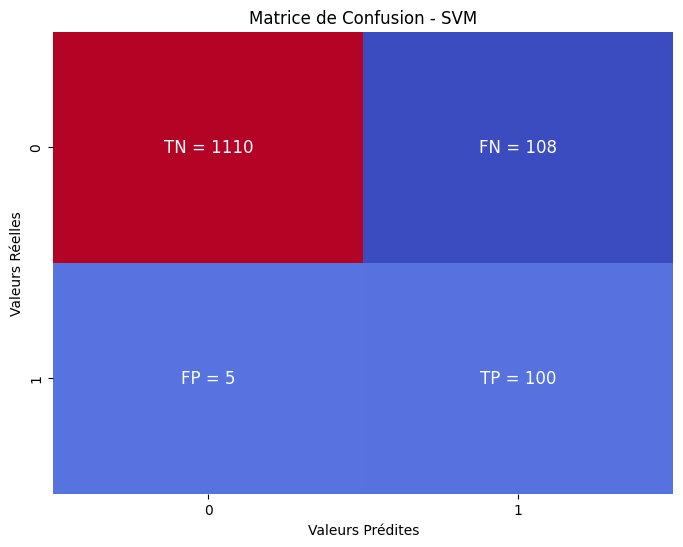

In [6]:
# Matrice de confusion
conf_matrix = confusion_matrix(y_test, y_pred)
print("Matrice de Confusion (SVM) :\n", conf_matrix)

# Visualisation
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=False, fmt="d", cmap="coolwarm", cbar=False)

# Calcul des valeurs TP, TN, FP, FN
TN, FP, FN, TP = conf_matrix.ravel()

# Ajout des valeurs sur le graphique
plt.text(0.5, 0.5, f'TN = {TN}', ha='center', va='center', color='white', fontsize=12)
plt.text(0.5, 1.5, f'FP = {FP}', ha='center', va='center', color='white', fontsize=12)
plt.text(1.5, 0.5, f'FN = {FN}', ha='center', va='center', color='white', fontsize=12)
plt.text(1.5, 1.5, f'TP = {TP}', ha='center', va='center', color='white', fontsize=12)
plt.title("Matrice de Confusion - SVM")
plt.ylabel('Valeurs Réelles')
plt.xlabel('Valeurs Prédites')
plt.show()

### 6.2 Rapport de classification

In [7]:
# Rapport de classification
class_report = classification_report(y_test, y_pred)
print("Rapport de Classification (SVM) :\n", class_report)

Rapport de Classification (SVM) :
               precision    recall  f1-score   support

           0       0.91      1.00      0.95      1115
           1       0.95      0.48      0.64       208

    accuracy                           0.91      1323
   macro avg       0.93      0.74      0.80      1323
weighted avg       0.92      0.91      0.90      1323



### 6.3 Score AUC-ROC

In [8]:
# AUC-ROC
roc_auc = roc_auc_score(y_test, y_proba)
print(f"AUC-ROC (SVM) : {roc_auc:.4f}")

AUC-ROC (SVM) : 0.9226


### 6.4 Courbe ROC

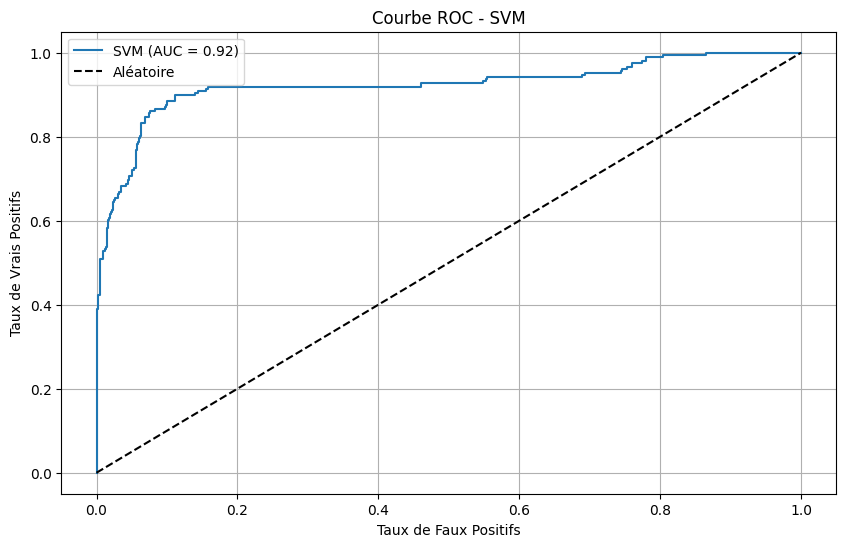

In [9]:
# Courbe ROC
fpr, tpr, thresholds = roc_curve(y_test, y_proba)

plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, label=f"SVM (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], 'k--', label="Aléatoire")
plt.xlabel("Taux de Faux Positifs")
plt.ylabel("Taux de Vrais Positifs")
plt.title("Courbe ROC - SVM")
plt.legend()
plt.grid(True)
plt.show()

## 7. Sauvegarde du modèle et des résultats

In [10]:
# Sauvegarde du modèle
with open('Data/svm_model.pkl', 'wb') as f:
    pickle.dump(svm, f)

# Sauvegarde des résultats
results = {
    'model_name': 'SVM',
    'predictions': y_pred,
    'probabilities': y_proba,
    'auc_roc': roc_auc,
    'confusion_matrix': conf_matrix
}

with open('Data/svm_results.pkl', 'wb') as f:
    pickle.dump(results, f)

print("Modèle et résultats sauvegardés!")

Modèle et résultats sauvegardés!


## Résumé

Ce notebook a permis de :
1. Charger les données préparées
2. Entraîner un modèle SVM
3. Évaluer ses performances avec plusieurs métriques
4. Sauvegarder le modèle et les résultats pour comparaison ultérieure